# 05. Hypothesis tests (action items C2, C3, C4, G5)

**C3: original proposal hypotheses P1–P3.** Registered in the proposal, so they are pre-registered. Reported as descriptive checks in the appendix and Holm-corrected as their own family of three.

**How to read the intervals.** A 95% interval comes from a procedure that captures the true value in about 95% of repeated samples. It is not a 95% probability statement about this particular interval.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests

from src.config import ALPHA, FIGURES, SEED, TABLES
from src.data import load_raw
from src.stats_utils import boot_ci_diff, cliffs_delta, fmt_ci, hedges_g, risk_difference, risk_ratio

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

df = load_raw()
print(df.shape, "| strokes:", df["stroke"].sum())

(5110, 11) | strokes: 249


## Part A. Proposal hypotheses P1–P3 (appendix)

Pre-registered in the proposal. Descriptive checks, Holm-corrected as their own family of three.

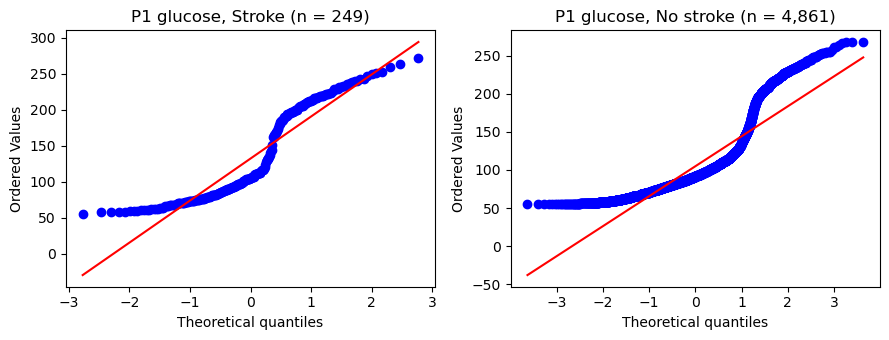

,hypothesis,stroke_mean,no_stroke_mean,mean_diff,ci_low,ci_high,hedges_g,cliffs_delta,welch_p,mwu_p
0,P1 glucose,132.5447,104.7955,27.7492,20.0527,35.4622,0.618,0.2213,0.0,0.0


In [2]:
# Split glucose into the two groups
g1 = df.loc[df["stroke"] == 1, "avg_glucose_level"].to_numpy()   # stroke
g0 = df.loc[df["stroke"] == 0, "avg_glucose_level"].to_numpy()   # no stroke

# Assumption check: is glucose Normal in each group? (Q–Q plot: points on the line = Normal)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, x, name in [(axes[0], g1, "Stroke"), (axes[1], g0, "No stroke")]:
    stats.probplot(x, dist="norm", plot=ax)
    ax.set_title(f"P1 glucose, {name} (n = {len(x):,})")
fig.tight_layout()
fig.savefig(FIGURES / "hyp_p1_glucose_qq.png", bbox_inches="tight")
plt.show()

# Main test + fallbacks
welch = stats.ttest_ind(g1, g0, equal_var=False)            # Welch t-test (compares means)
mwu = stats.mannwhitneyu(g1, g0, alternative="two-sided")   # Mann–Whitney (no Normality needed)
diff, lo, hi = boot_ci_diff(g1, g0, seed=SEED)              # bootstrap CI for the mean difference

p1 = pd.DataFrame([{
    "hypothesis": "P1 glucose",
    "stroke_mean": g1.mean(), "no_stroke_mean": g0.mean(),
    "mean_diff": diff, "ci_low": lo, "ci_high": hi,
    "hedges_g": hedges_g(g1, g0),          # size of the difference in SD units
    "cliffs_delta": cliffs_delta(g1, g0),  # P(stroke higher) − P(no-stroke higher)
    "welch_p": welch.pvalue, "mwu_p": mwu.pvalue,
}])
p1.to_csv(TABLES / "hyp_p1_glucose.csv", index=False)
display(p1.round(4))

**P1 assumption check.** Glucose is not Normal in either group. The Q–Q plots show two clusters: most patients fall around 55–130 mg/dL and a smaller group around 170–270 mg/dL, with few values in between (consistent with Track 2's two-population fit). The lower tail is truncated near 55 mg/dL. The high-glucose cluster is visibly larger among stroke patients (the jump occurs at a lower quantile).

Consequences: (1) Welch's t-test compares means and remains approximately valid through the central limit theorem at n = 249 and 4,861, but we also report the Mann–Whitney test and a bootstrap CI, which do not assume Normality; (2) with two clusters, the mean difference mainly reflects how many patients are in the high-glucose cluster, so it should be read as a blunt summary.

**P1 result.** Stroke patients had a mean glucose 27.7 mg/dL higher than non-stroke patients (132.5 vs 104.8; 95% bootstrap CI 20.1 to 35.5; Welch p < 0.001; Mann–Whitney p < 0.001). Hedges' g = 0.62 (medium), but Cliff's δ = 0.22 (small): a random stroke patient has higher glucose than a random non-stroke patient about 61% of the time. The gap between the two effect sizes matches the Q–Q plots: the difference is driven mainly by the larger high-glucose cluster among stroke patients, not by a shift of the whole distribution. This is a descriptive check (proposal hypothesis); it does not adjust for age.

In [3]:
# 2×2 table: hypertension (rows) × stroke (columns)
table = pd.crosstab(df["hypertension"], df["stroke"])
display(table)

# Assumption check for χ²: every EXPECTED count should be at least 5
res = stats.chi2_contingency(table, correction=False)
expected = pd.DataFrame(res.expected_freq, index=table.index, columns=table.columns)
print("Expected counts if hypertension and stroke were unrelated:")
display(expected.round(1))

fisher = stats.fisher_exact(table)   # fallback test, exact (no expected-count rule)

# Effect sizes: stroke risk WITH hypertension vs WITHOUT
k1 = int(((df["hypertension"] == 1) & (df["stroke"] == 1)).sum()); n1 = int((df["hypertension"] == 1).sum())
k0 = int(((df["hypertension"] == 0) & (df["stroke"] == 1)).sum()); n0 = int((df["hypertension"] == 0).sum())
rd, rd_lo, rd_hi = risk_difference(k1, n1, k0, n0)   # difference in stroke risk (Newcombe CI)
rr, rr_lo, rr_hi = risk_ratio(k1, n1, k0, n0)        # how many times higher the risk is
cramers_v = np.sqrt(res.statistic / table.to_numpy().sum())

p2 = pd.DataFrame([{
    "hypothesis": "P2 hypertension",
    "risk_hyp": k1 / n1, "risk_no_hyp": k0 / n0,
    "risk_diff": rd, "rd_ci_low": rd_lo, "rd_ci_high": rd_hi,
    "risk_ratio": rr, "rr_ci_low": rr_lo, "rr_ci_high": rr_hi,
    "cramers_v": cramers_v, "min_expected": expected.to_numpy().min(),
    "chi2_p": res.pvalue, "fisher_p": fisher.pvalue,
}])
p2.to_csv(TABLES / "hyp_p2_hypertension.csv", index=False)
display(p2.round(4))
print(f"P1 Welch p = {welch.pvalue:.2e}, MWU p = {mwu.pvalue:.2e}")
print(f"P2 chi2 p = {res.pvalue:.2e}, Fisher p = {fisher.pvalue:.2e}")

stroke,0,1
hypertension,,
0,4429,183
1,432,66


Expected counts if hypertension and stroke were unrelated:


stroke,0,1
hypertension,,
0,4387.3,224.7
1,473.7,24.3


,hypothesis,risk_hyp,risk_no_hyp,risk_diff,rd_ci_low,rd_ci_high,risk_ratio,rr_ci_low,rr_ci_high,cramers_v,min_expected,chi2_p,fisher_p
0,P2 hypertension,0.1325,0.0397,0.0929,0.0652,0.1259,3.34,2.5605,4.357,0.1279,24.2665,0.0,0.0


P1 Welch p = 2.40e-11, MWU p = 3.64e-09
P2 chi2 p = 6.07e-20, Fisher p = 4.55e-15


**P2 result.** Stroke occurred in 13.3% of hypertensive patients (66/498) versus 4.0% of others (183/4,612): a risk difference of 9.3 percentage points (95% Newcombe CI 6.5 to 12.6) and a risk ratio of 3.34 (2.56 to 4.36). χ² p = 6.1 × 10⁻²⁰; all expected counts ≥ 24.3, so the χ² approximation holds (Fisher's exact p = 4.6 × 10⁻¹⁵ agrees). Cramér's V is only 0.13 because both hypertension and stroke are uncommon; the risk ratio is the clinically relevant summary. This is a crude association: hypertensive patients are older, so part of it reflects age (see the age-adjusted estimate below and H1).

In [4]:
crude = smf.logit("stroke ~ hypertension", data=df).fit(disp=0)
adj = smf.logit("stroke ~ hypertension + age", data=df).fit(disp=0)
out = pd.DataFrame({
    "model": ["crude", "adjusted for age"],
    "OR_hypertension": [np.exp(crude.params["hypertension"]), np.exp(adj.params["hypertension"])],
    "ci_low": [np.exp(crude.conf_int().loc["hypertension", 0]), np.exp(adj.conf_int().loc["hypertension", 0])],
    "ci_high": [np.exp(crude.conf_int().loc["hypertension", 1]), np.exp(adj.conf_int().loc["hypertension", 1])],
})
out.to_csv(TABLES / "hyp_p2_crude_vs_age_adjusted.csv", index=False)
display(out.round(3))

,model,OR_hypertension,ci_low,ci_high
0,crude,3.698,2.744,4.982
1,adjusted for age,1.596,1.166,2.184


**P2 adjusted for age (exploratory).** The crude odds ratio for hypertension is 3.70 (95% Wald CI 2.74 to 4.98). Adjusted for age it falls to 1.60 (1.17 to 2.18). Most of the crude association reflects the older age of hypertensive patients, although an association remains after adjustment. This motivates H1, which asks what hypertension and other modifiable factors add beyond age. Not part of the Holm family.

In [5]:
# Logistic regression: does the log-odds of stroke rise with age?
m0 = smf.logit("stroke ~ 1", data=df).fit(disp=0)     # no predictors (everyone same risk)
m1 = smf.logit("stroke ~ age", data=df).fit(disp=0)   # risk depends on age

# Likelihood-ratio test: does adding age make the model fit clearly better?
lr = 2 * (m1.llf - m0.llf)
p_two = stats.chi2.sf(lr, df=1)
beta = m1.params["age"]
p3_p = p_two / 2 if beta > 0 else 1 - p_two / 2      # one-sided (H1: risk rises with age)

# Effect size: odds ratio per 10 years (Wald CI)
lo, hi = m1.conf_int().loc["age"]
or10, or10_lo, or10_hi = np.exp(10 * beta), np.exp(10 * lo), np.exp(10 * hi)

# Assumption check: is a straight line in age good enough? (spline vs linear, LR test)
ms = smf.logit("stroke ~ bs(age, df=4)", data=df).fit(disp=0)
lr_lin = 2 * (ms.llf - m1.llf)
p_lin = stats.chi2.sf(lr_lin, df=3)

# Physician units: predicted stroke risk at example ages
risk = m1.predict(pd.DataFrame({"age": [40, 60, 80]}))

p3 = pd.DataFrame([{
    "hypothesis": "P3 age", "or_per_10y": or10, "ci_low": or10_lo, "ci_high": or10_hi,
    "lr_stat": lr, "p_one_sided": p3_p,
    "linearity_lr": lr_lin, "linearity_p": p_lin,
    "risk_age40": risk[0], "risk_age60": risk[1], "risk_age80": risk[2],
}])
p3.to_csv(TABLES / "hyp_p3_age.csv", index=False)
display(p3.round(4))
print(f"P3 one-sided p = {p3_p:.2e}, linearity p = {p_lin:.3g}")

,hypothesis,or_per_10y,ci_low,ci_high,lr_stat,p_one_sided,linearity_lr,linearity_p,risk_age40,risk_age60,risk_age80
0,P3 age,2.1112,1.9171,2.3251,374.1167,0.0,8.3606,0.0391,0.0142,0.0602,0.2221


P3 one-sided p = 1.19e-83, linearity p = 0.0391


,k,n,mid,rate,ci_low,ci_high
age_band,,,,,,
"[0, 20)",2,966,9.6874,0.0021,0.0006,0.0075
"[20, 30)",0,549,24.5209,0.0000,0.0000,0.0069
"[30, 40)",6,655,34.5695,0.0092,0.0042,0.0198
"[40, 50)",12,730,44.5014,0.0164,0.0094,0.0285
"[50, 60)",48,834,54.4065,0.0576,0.0437,0.0755
"[60, 70)",47,621,64.0789,0.0757,0.0574,0.0992
"[70, 83)",134,755,76.5179,0.1775,0.1519,0.2063


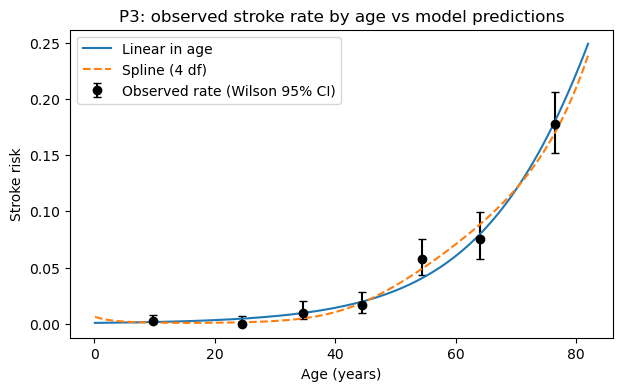

In [6]:
from src.stats_utils import wilson_ci

# Observed stroke rate in age bands, with 95% Wilson CIs
df["age_band"] = pd.cut(df["age"], bins=[0, 20, 30, 40, 50, 60, 70, 83], right=False)
obs = df.groupby("age_band", observed=True).agg(k=("stroke", "sum"), n=("stroke", "size"), mid=("age", "mean"))
ci = np.array([wilson_ci(int(k), int(n)) for k, n in zip(obs["k"], obs["n"])])
display(obs.assign(rate=ci[:, 0], ci_low=ci[:, 1], ci_high=ci[:, 2]).round(4))

# Compare with the straight-line model and the flexible spline
grid = pd.DataFrame({"age": np.linspace(df["age"].min(), df["age"].max(), 200)})
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(obs["mid"], ci[:, 0], yerr=[ci[:, 0] - ci[:, 1], ci[:, 2] - ci[:, 0]],
            fmt="o", color="black", capsize=3, label="Observed rate (Wilson 95% CI)")
ax.plot(grid["age"], m1.predict(grid), label="Linear in age")
ax.plot(grid["age"], ms.predict(grid), "--", label="Spline (4 df)")
ax.set_xlabel("Age (years)"); ax.set_ylabel("Stroke risk")
ax.set_title("P3: observed stroke rate by age vs model predictions")
ax.legend()
fig.savefig(FIGURES / "hyp_p3_age_fit.png", bbox_inches="tight")
plt.show()

**P3 result.** Stroke odds roughly double with each decade of age (OR per 10 years 2.11, 95% Wald CI 1.92 to 2.33; LR test χ² = 374.1, one-sided p = 1.2 × 10⁻⁸³). Predicted risk from the linear model: 1.4% at 40, 6.0% at 60, 22.2% at 80. The logistic regression itself serves as the trend test promised in the proposal.

**Assumption check.** A 4-df spline fits better than a linear age term (LR χ² = 8.36, 3 df, p = 0.039): modest evidence that the log-odds are not exactly linear in age. The conclusion that risk rises with age is unaffected, and the figure shows the departure is small in practice: both curves pass through every observed age-band rate within its 95% CI. The linear model slightly under-predicts risk around ages 50–65 and slightly over-predicts in the over-75s; the spline's small rise below age 5 is an artefact of almost no events in children. Because of this check, age enters the decision-relevant models (H1) as a spline.

In [7]:
# Primary test for each, as written in the proposal:
# P1: "Mann–Whitney U if normality fails"  -> normality failed, so MWU is primary
# P2: chi-square;  P3: LR test of age
family = pd.DataFrame({
    "hypothesis": ["P1 glucose", "P2 hypertension", "P3 age"],
    "test": ["Mann–Whitney U", "χ² (no continuity correction)", "LR test, one-sided"],
    "p_raw": [mwu.pvalue, res.pvalue, p3_p],
})
family["p_holm"] = multipletests(family["p_raw"], method="holm")[1]
family.to_csv(TABLES / "hyp_c3_holm.csv", index=False)
display(family)

,hypothesis,test,p_raw,p_holm
0,P1 glucose,Mann–Whitney U,3.640367e-09,3.640367e-09
1,P2 hypertension,χ² (no continuity correction),6.068123e-20,1.213625e-19
2,P3 age,"LR test, one-sided",1.188094e-83,3.564282e-83


**C3 summary (Holm-corrected family of three).** All three proposal hypotheses are supported: glucose differs by stroke status (Mann–Whitney, Holm p = 3.6 × 10⁻⁹), hypertension is associated with stroke (χ², Holm p = 1.2 × 10⁻¹⁹), and stroke risk rises with age (LR test, Holm p = 3.6 × 10⁻⁸³). As the professor noted, these confirm what clinicians already know; they are reported as descriptive checks. The decision-relevant hypotheses (H1, H2) are tested separately.

## Part B. Decision-relevant hypotheses (H1)

To be run only after H1 and H2 are committed to `docs/hypotheses.md` (action item C1). H2 runs in `08_fairness.ipynb`, because it needs Track 3's out-of-fold predictions.

In [ ]:
import statsmodels.api as sm

from src.config import DATA_INTERIM
from src.hypotheses import (h1_analysis, h1_formulas, h5_formulas, h_frame, lr_test,
                            profile_ci, risk_at, spline_vs_linear)

# Same analysis frame as Track 3: the one gender "Other" record dropped (n = 5,109)
hd = h_frame(load_raw())
print(f"n = {len(hd):,}, strokes = {hd['stroke'].sum()}")

### H1: Do modifiable risk factors improve the referral decision beyond age?

Registered 2026-11-11 in `docs/hypotheses.md`.

- **base** = 4-df age spline + sex + heart disease (what the doctor knows without a lab test)
- **full** = base + hypertension + glucose (per 50 mg/dL) + smoking (4 levels, "Unknown" kept)
- **Primary test:** likelihood-ratio (LR) test, full vs base, 5 df. It asks: "do the 5 added terms improve the fit by more than chance would?"
- **Effect sizes:** ΔAUC (here, no cost ratio needed) and ΔNB at p\* (added once R is set, action item A1).

Out-of-fold predictions use the same 5 folds as Track 3 (checked: identical fold assignment).

In [ ]:
h1_main, h1_oof = h1_analysis(hd, "H1 main: full data")
h1_oof.to_csv(DATA_INTERIM / "h1_oof.csv", index=False)   # kept for ΔNB once R is set

f_base, f_full = h1_formulas(hd)
print("base:", f_base)
print("full:", f_full)
print(f"\nLR test: χ² = {h1_main['lr_stat']:.2f}, {h1_main['lr_df']} df, p = {h1_main['p_value']:.3g}")
print(f"Events per parameter: {h1_main['events']} / {h1_main['params_big']} = {h1_main['events_per_param']:.1f}")
print(f"OOF AUC: base {h1_main['auc_base']:.3f}, full {h1_main['auc_full']:.3f}; "
      f"ΔAUC {fmt_ci(h1_main['delta_auc'], h1_main['delta_auc_low'], h1_main['delta_auc_high'], digits=3)}")

# Odds ratios of the 5 added terms in the full model (descriptive; the LR test above is the test)
fit_full = smf.logit(f_full, hd).fit(disp=0)
added = [c for c in fit_full.params.index if c in ("hypertension", "glu50") or c.startswith("C(smoking")]
ci = fit_full.conf_int().loc[added]
h1_or = pd.DataFrame({"term": added, "OR": np.exp(fit_full.params[added]).to_numpy(),
                      "ci_low": np.exp(ci[0]).to_numpy(), "ci_high": np.exp(ci[1]).to_numpy(),
                      "wald_p": fit_full.pvalues[added].to_numpy()})
h1_or.to_csv(TABLES / "hyp_h1_or.csv", index=False)
display(h1_or.round(3))

In [ ]:
# H1 assumption check: is glucose linear on the log-odds scale?
# Registered check: 3-df spline vs linear (2-df LR test). The 4-df version (3-df test) matches Track 3's G3.
h1_lin = pd.DataFrame([spline_vs_linear(hd, f_full, "glu50", k) for k in (3, 4)])
h1_lin.insert(0, "model", "H1 full")
h1_lin.to_csv(TABLES / "hyp_h1_linearity.csv", index=False)
display(h1_lin.round(4))

### Sensitivity analyses for H1 (registered; not in the Holm family)

- **G5 adults only** (age ≥ 18): children have almost no strokes, so check that they don't drive the result.
- **H1 + BMI, complete cases** (BMI recorded, n = 4,908): BMI added to both models.

In [ ]:
adults = hd[hd["age"] >= 18].reset_index(drop=True)
g5_row, g5_oof = h1_analysis(adults, "G5: adults only (age >= 18)")
g5_oof.to_csv(DATA_INTERIM / "h1_oof_adults.csv", index=False)

cc = hd[hd["bmi"].notna()].reset_index(drop=True)
bmi_row, bmi_oof = h1_analysis(cc, "H1 + BMI: complete cases", with_bmi=True)
bmi_oof.to_csv(DATA_INTERIM / "h1_oof_bmi_cc.csv", index=False)

h1_table = pd.DataFrame([h1_main, g5_row, bmi_row])
h1_table.to_csv(TABLES / "hyp_h1.csv", index=False)
display(h1_table.round(4))

### H5 (appendix, secondary): in patients aged 60+, does glucose add information beyond what the doctor already knows?

Registered 2026-11-11. Base = age + sex + hypertension + heart disease; full adds glucose (per 50 mg/dL). LR test, 1 df. Effect size: OR per 50 mg/dL with a profile-likelihood CI, plus absolute risk at glucose 90 vs 200 mg/dL for a typical patient in the subgroup. Raw p-value; not in the H1/H2 Holm family.

In [ ]:
old = hd[hd["age"] >= 60].reset_index(drop=True)
b5, f5 = h5_formulas()
h5 = lr_test(old, b5, f5)
beta, lo, hi = profile_ci(old, b5, "glu50")
wald = h5["_big"].conf_int().loc["glu50"]

h5_row = pd.DataFrame([{
    "hypothesis": "H5 glucose, age >= 60", "n": h5["n"], "events": h5["events"],
    "events_per_param": h5["events_per_param"],
    "OR_per_50": np.exp(beta), "profile_ci_low": np.exp(lo), "profile_ci_high": np.exp(hi),
    "wald_ci_low": np.exp(wald[0]), "wald_ci_high": np.exp(wald[1]),
    "lr_stat": h5["lr_stat"], "lr_df": h5["lr_df"], "p_value": h5["p_value"],
}])
h5_row.to_csv(TABLES / "hyp_h5.csv", index=False)
display(h5_row.round(4))

# Assumption checks: linearity of glucose and age (registered: 3-df spline; 4-df shown too)
h5_lin = pd.DataFrame([spline_vs_linear(old, f5, t, k) for t in ("glu50", "age") for k in (3, 4)])
h5_lin.insert(0, "model", "H5 full")
h5_lin.to_csv(TABLES / "hyp_h5_linearity.csv", index=False)
display(h5_lin.round(4))

# Physician units: risk for a typical patient in the subgroup (median age, most common sex,
# most common hypertension / heart-disease status) at glucose 90 vs 200 mg/dL
glm5 = smf.glm(f5, old, family=sm.families.Binomial()).fit()
typical = pd.DataFrame({
    "age": old["age"].median(), "gender": old["gender"].mode()[0],
    "hypertension": old["hypertension"].mode()[0], "heart_disease": old["heart_disease"].mode()[0],
    "glu50": [90 / 50, 200 / 50],
}, index=["glucose 90 mg/dL", "glucose 200 mg/dL"])
h5_risk = typical.join(risk_at(glm5, typical))
h5_risk.to_csv(TABLES / "hyp_h5_risk.csv", index_label="scenario")
display(h5_risk.round(4))

**Results and interpretation:** to be written after the first run.

**Still to come (needs R, action item A1):** ΔNB for H1 (and for G5 and the BMI version) at p\* = 1/(1 + R) and over `COST_RATIO_GRID`, using the saved OOF files; H2 and the error-rate table in a later notebook (they need Track 3's predictions); Holm across H1 and H2.